# 01 · EDA: Prediksi Tingkat Kerusakan Bangunan Gempa Gorkha 2015

Notebook pertama dari tiga. Isinya tahap **1–3** dari workflow analisis:

1. Pemahaman data & problem statement
2. Data cleaning
3. Exploratory Data Analysis (EDA), termasuk pemeriksaan kebocoran data

Tahap 4–10 ada di `02_modeling.ipynb`, dan pembuatan submission di `03_submission.ipynb`.
Semua figur disimpan ke `reports/figures/`.

In [1]:
import sys, os, time, warnings, json
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

from scripts.preprocess import SEED, GRADES, CAT_COLS, load_data, add_unsupervised_features

np.random.seed(SEED)
DATA_DIR = '../data'
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)
T0 = time.time()

# Palet: rampa biru berurutan untuk grade 1 -> 5 (target ordinal)
GRADE_COLORS = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']
ACCENT, ACCENT2 = '#2a78d6', '#eb6834'
mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold', 'font.size': 10})

def savefig(name):
    # simpan figur ke reports/figures lalu tampilkan
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}.png', dpi=120, bbox_inches='tight'); plt.show()

## 1. Pemahaman Data & Problem Statement

**Problem statement.** Dari karakteristik struktural bangunan *sebelum* gempa 25 April 2015 (Mw 7,8),
prediksi `damage_grade` (Grade 1 = rusak ringan … Grade 5 = runtuh). Ini klasifikasi **multikelas**
dengan target **ordinal**. Metrik lomba adalah **Macro F1**, jadi kelima grade berbobot sama dan grade
minoritas sama pentingnya dengan grade mayoritas.

In [2]:
train, test, y = load_data(DATA_DIR)
print('train:', train.shape, '| test:', test.shape)
display(train.head())
print(train.dtypes)

train: (533465, 17) | test: (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


building_id               int64
district_id               int64
vdcmun_id                 int64
ward_id                   int64
count_floors_pre_eq       int64
age_building              int64
plinth_area_sq_ft         int64
height_ft_pre_eq          int64
land_surface_condition      str
foundation_type             str
roof_type                   str
ground_floor_type           str
other_floor_type            str
position                    str
plan_configuration          str
damage_grade                str
superstructure              str
dtype: object


In [3]:
dist = pd.Series(y).value_counts().sort_index()
display(pd.DataFrame({'jumlah': dist, 'proporsi': (dist / len(y)).round(4)}))

,jumlah,proporsi
1,55170,0.1034
2,61080,0.1145
3,95488,0.1790
4,128691,0.2412
5,193036,0.3619


**Struktur `building_id`.** ID terdiri atas 12 digit: digit 1–6 = *ward lama* (selalu bersarang di dalam `ward_id`),
digit 7–10 = nomor urut survei, sehingga prefiks 10 digit membentuk klaster sekitar 7 bangunan bertetangga.
Ini informasi lokasi yang jauh lebih halus daripada `ward_id`, dan ada di file lomba sendiri (bukan data eksternal).

In [4]:
s = train.building_id.astype(str)
for L in [2, 4, 6, 8, 9, 10, 12]:
    print(f'prefiks {L:2d} digit -> {s.str[:L].nunique():7d} grup')
print('ward_id unik:', train.ward_id.nunique())
print('ward lama (prefiks 6) bersarang di ward_id:', (train.groupby(s.str[:6]).ward_id.nunique() == 1).all())

prefiks  2 digit ->      11 grup
prefiks  4 digit ->     627 grup


prefiks  6 digit ->    5666 grup
prefiks  8 digit ->    6120 grup


prefiks  9 digit ->   10257 grup
prefiks 10 digit ->   74823 grup


prefiks 12 digit ->  533465 grup
ward_id unik: 945


ward lama (prefiks 6) bersarang di ward_id: True


## 2. Data Cleaning

In [5]:
print('Missing value train:', int(train.isna().sum().sum()), '| test:', int(test.isna().sum().sum()))
print('Duplikat building_id:', train.building_id.duplicated().sum(),
      '| irisan ID train-test:', len(set(train.building_id) & set(test.building_id)))
num_cols = ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']
display(train[num_cols].describe(percentiles=[.01, .5, .99]).T)
print('umur = 999 (kode khusus):', (train.age_building == 999).sum())
for c in CAT_COLS:
    baru = set(test[c].unique()) - set(train[c].unique())
    print(f'{c:24s} kategori={train[c].nunique():2d}  kategori baru di test: {baru or "-"}')
for c in ['district_id', 'vdcmun_id', 'ward_id']:
    print(f'{c:12s}: lokasi test yang tidak ada di train = {len(set(test[c]) - set(train[c]))}')
feat_cols = [c for c in train.columns if c not in ['building_id', 'damage_grade']]
g = train.groupby(feat_cols).damage_grade.nunique()
print(f'Grup input identik dengan grade berbeda: {(g > 1).sum()} (derau label alami survei)')

Missing value train: 0 | test: 0


Duplikat building_id: 0 | irisan ID train-test: 0


,count,mean,std,min,1%,50%,99%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,1.0,2.0,4.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,1.0,16.0,90.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,120.0,358.0,1222.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,6.0,16.0,32.0,99.0


umur = 999 (kode khusus): 2198
land_surface_condition   kategori= 3  kategori baru di test: -
foundation_type          kategori= 5  kategori baru di test: -


roof_type                kategori= 3  kategori baru di test: -


ground_floor_type        kategori= 5  kategori baru di test: -
other_floor_type         kategori= 4  kategori baru di test: -
position                 kategori= 4  kategori baru di test: -


plan_configuration       kategori=10  kategori baru di test: -


superstructure           kategori=11  kategori baru di test: -
district_id : lokasi test yang tidak ada di train = 0


vdcmun_id   : lokasi test yang tidak ada di train = 0
ward_id     : lokasi test yang tidak ada di train = 0


Grup input identik dengan grade berbeda: 10695 (derau label alami survei)


**Keputusan cleaning** (diimplementasikan di `scripts/preprocess.py::BuildingFeatures`)
- Tidak ada missing value dan tidak ada kategori baru di test, jadi tidak perlu imputasi untuk model pohon.
- `age_building = 999` adalah kode khusus: dibuat flag `age_999` dan versi umur yang di-*cap* (`age_cap`).
- Outlier luas/tinggi tidak dibuang (model pohon tahan outlier); ditambahkan rasio per lantai.
- Banyak bangunan dengan input identik punya grade berbeda: plafon skor jauh di bawah 1.

## 3. Exploratory Data Analysis

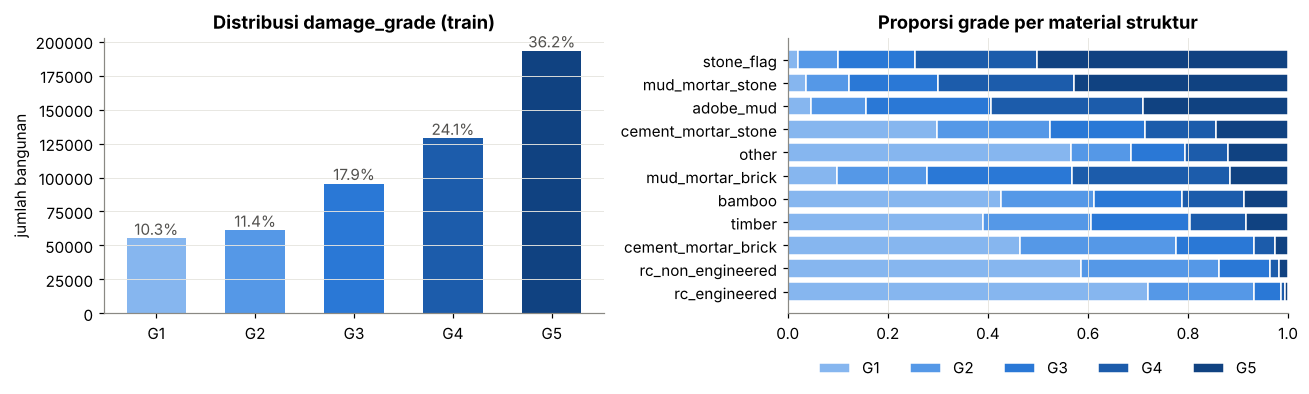

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.bar([f'G{g}' for g in GRADES], dist.values, color=GRADE_COLORS, width=0.6)
for i, v in enumerate(dist.values):
    ax.text(i, v, f'{v/len(y):.1%}', ha='center', va='bottom', color='#52514e')
ax.set_title('Distribusi damage_grade (train)'); ax.set_ylabel('jumlah bangunan'); ax.grid(axis='x', visible=False)
ax = axes[1]
tab = pd.crosstab(train.superstructure.str.replace('has_superstructure_', ''), y, normalize='index')
tab = tab.loc[tab[5].sort_values().index]
left = np.zeros(len(tab))
for k, g in enumerate(GRADES):
    ax.barh(tab.index, tab[g], left=left, color=GRADE_COLORS[k], label=f'G{g}', edgecolor='white', linewidth=1)
    left += tab[g].values
ax.set_title('Proporsi grade per material struktur'); ax.set_xlim(0, 1); ax.grid(axis='y', visible=False)
ax.legend(ncol=5, loc='lower center', bbox_to_anchor=(0.5, -0.28), frameon=False)
savefig('eda_distribusi_grade_material')

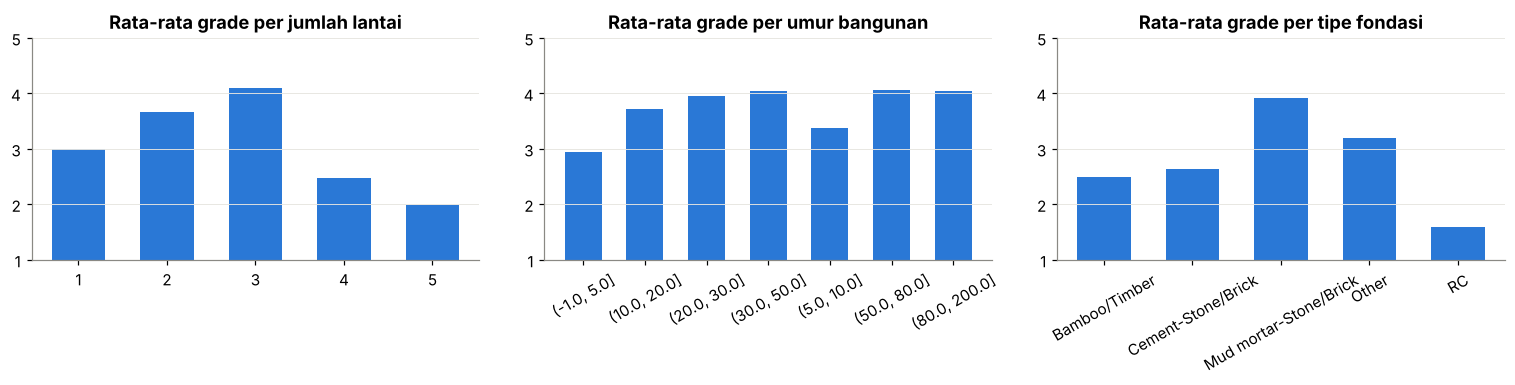

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
def mean_grade_by(vals, ax, judul, rot=0, min_n=500):
    m = pd.Series(y).groupby(np.asarray(vals)).agg(['mean', 'size'])
    m = m[m['size'] > min_n]
    ax.bar(m.index.astype(str), m['mean'], color=ACCENT, width=0.6)
    ax.set_title(judul); ax.set_ylim(1, 5); ax.tick_params(axis='x', rotation=rot); ax.grid(axis='x', visible=False)
mean_grade_by(train.count_floors_pre_eq, axes[0], 'Rata-rata grade per jumlah lantai')
mean_grade_by(pd.cut(train.age_building.where(train.age_building < 999), [-1, 5, 10, 20, 30, 50, 80, 200]).astype(str),
              axes[1], 'Rata-rata grade per umur bangunan', rot=30)
mean_grade_by(train.foundation_type, axes[2], 'Rata-rata grade per tipe fondasi', rot=30)
savefig('eda_lantai_umur_fondasi')

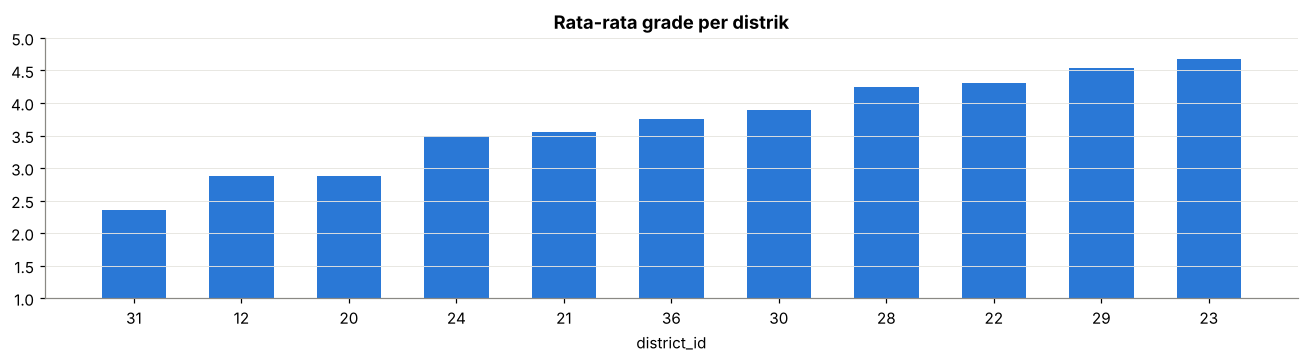

,level,jumlah_grup,rata2_ukuran,std_grade_dalam_grup
0,district_id,11,48496.8,1.114
1,vdcmun_id,110,4849.7,1.016
2,ward_id,945,564.5,0.954
3,p6,5666,94.2,0.834
4,p10,74823,7.1,0.737


P(grade sama dengan tetangga ID berikutnya) = 0.5204 | kalau acak = 0.245


In [8]:
m = pd.Series(y).groupby(train.district_id.values).mean().sort_values()
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.bar(m.index.astype(str), m.values, color=ACCENT, width=0.6)
ax.set_ylim(1, 5); ax.set_title('Rata-rata grade per distrik'); ax.set_xlabel('district_id'); ax.grid(axis='x', visible=False)
savefig('eda_grade_per_distrik')

X_tr, X_te = add_unsupervised_features(train, test)
rows = []
for c in ['district_id', 'vdcmun_id', 'ward_id', 'p6', 'p10']:
    g = pd.Series(y).groupby(X_tr[c].values)
    rows.append({'level': c, 'jumlah_grup': g.ngroups, 'rata2_ukuran': round(len(y) / g.ngroups, 1),
                 'std_grade_dalam_grup': round(g.std().mean(), 3)})
display(pd.DataFrame(rows))
o = np.argsort(train.building_id.values); ys = y[o]; w6 = X_tr.p6.values[o]
same = w6[1:] == w6[:-1]
print('P(grade sama dengan tetangga ID berikutnya) =', round((ys[1:] == ys[:-1])[same].mean(), 4),
      '| kalau acak =', round(((dist / len(y)) ** 2).sum(), 4))

Semakin halus level lokasinya, semakin kecil sebaran grade di dalam grup, dan bangunan bertetangga dalam urutan
`building_id` dua kali lebih sering ber-grade sama dibanding pasangan acak. Kerusakan sangat ditentukan oleh guncangan
lokal, sehingga fitur lokasi halus dan tetangga menjadi inti feature engineering di `02_modeling.ipynb`.

### Pemeriksaan kebocoran data
- ID train dan test berselang-seling: pemisahan train/test **acak**. Adversarial validation memberi AUC ≈ 0,50, jadi `StratifiedKFold` acak aman.
- Urutan baris tidak informatif.
- Train + test = 762.094 bangunan, persis ukuran data publik *2015 Nepal Earthquake Open Data*. Label test kemungkinan bisa dicocokkan dari sumber itu. **Ini tidak dipakai** karena melanggar semangat lomba.
- Semua fitur berbasis label dihitung *fold-safe* lewat `LocationTargetEncoder` (cross-fitting), lihat `02_modeling.ipynb`.

In [9]:
print(f'Selesai dalam {time.time()-T0:.0f} detik')

Selesai dalam 80 detik
